# BIM Uniform-Error Multi-Bid vs Fixed Single-Bid

This notebook reads existing results from `../outputs/bim`. It currently compares the 10,000-sample base uniform-error run (`b0.0`, error range `20.0`) with the fixed single-bid reference at `b40.0`. Change the filenames in the CSV-path cell to select another run or reference (`b0.0` through `b50.0` are available). Buy-foresight comparisons run only when the matching `_bid_perfect_foresight.csv` exists.

To generate new experiment CSVs in parallel from a terminal:

```sh
cd /Users/nlaws/projects/ferc_841_storage_models/code
julia --project=. --threads=1 -p 6 run_experiments.jl
```

Uncomment the desired experiment calls at the bottom of `run_experiments.jl` and set `n_samples` there (use `100` for a quick run). Run `run_uniform_error_multibid` and `run_single_bid` for the desired reference bid; optionally generate buy-foresight results with `bid_perfect_foresight = true`. Set the CSV paths below to the generated filenames. `-p 6` starts six worker processes; change it to suit your machine. Once the command finishes, restart the Julia kernel and run this notebook from the top to load and plot the results. The notebook only reads CSVs and generates plots.

BIM results and figures are stored under `outputs/bim` and `figures/bim`. The single-bid reference has one sample with one row per timestep. Terminal SOC valuation follows the selected run and single-bid reference. BIM multi-bid excludes degradation costs from its objective and prevents simultaneous charging and discharging with binary operating modes. Prices come from an LP re-solve with the optimal modes fixed. Reported ESS surplus subtracts degradation costs for comparison with the single-bid reference.


In [1]:
import Pkg
Pkg.activate(joinpath(@__DIR__, ".."))
using Random
include(joinpath(@__DIR__, "plotting.jl"))


  Activating project at `~/projects/ferc_841_storage_models/code`


plot_charge_by_time

In [2]:
using CSV
using DataFrames
using Statistics
using StatsPlots


FIGURE_DIR = joinpath(@__DIR__, "..", "figures", "bim")
mkpath(FIGURE_DIR)

function dollar_formatter(x)
    n = Int(round(x))
    s = string(abs(n))
    parts = []
    while length(s) > 3
        pushfirst!(parts, s[end-2:end])
        s = s[1:end-3]
    end
    pushfirst!(parts, s)
    body = join(parts, ",")
    return n < 0 ? "-\$" * body : "\$" * body
end


dollar_formatter (generic function with 1 method)

In [3]:
# --- CSV paths (relative to this notebook) ---
OUTPUT_DIR = joinpath(@__DIR__, "..", "outputs", "bim")
multi_uniform_csv_path = joinpath(OUTPUT_DIR, "uniform_error_multibid_results_base_b0.0_n10000_e20.0.csv")
single_csv_path = joinpath(OUTPUT_DIR, "singlebid_results_base_b40.0.csv")
multi_uniform_foresight_csv_path = replace(multi_uniform_csv_path, ".csv" => "_bid_perfect_foresight.csv")
has_buy_foresight = isfile(multi_uniform_foresight_csv_path)


false

In [4]:
multi_uniform_df = CSV.read(multi_uniform_csv_path, DataFrame)
single_df = CSV.read(single_csv_path, DataFrame)

multi_uniform_df_bid_perfect_foresight = has_buy_foresight ?
    CSV.read(multi_uniform_foresight_csv_path, DataFrame) : nothing
if !has_buy_foresight
    println("Skipping buy-foresight comparisons: CSV not found at $(multi_uniform_foresight_csv_path)")
end
# Buy foresight only changes multibid; both comparisons use the same single-bid reference.
single_df_bid_perfect_foresight = single_df

normalize_colname(n) = begin
    s = String(n)
    s = replace(s, '﻿' => "")
    s = lowercase(strip(s))
    s = replace(s, r"[^a-z0-9]+" => "_")
    s = strip(s, '_')
    Symbol(s)
end

for df in (multi_uniform_df, multi_uniform_df_bid_perfect_foresight, single_df)
    isnothing(df) && continue
    rename!(df, Dict(n => normalize_colname(n) for n in names(df)))
end

# Current single-bid CSVs store the terminal bid as b and omit sample/demand.
if !(:sample in propertynames(single_df))
    single_df.sample = ones(Int, nrow(single_df))
end
if !(:ess_bid in propertynames(single_df))
    single_df.ess_bid = single_df.b
end
if !(:demand in propertynames(single_df))
    demand_by_time = unique(select(multi_uniform_df, :time, :demand))
    @assert allunique(demand_by_time.time) "Expected the same demand across uniform-error samples."
    leftjoin!(single_df, demand_by_time; on = :time)
    @assert !any(ismissing, single_df.demand) "Missing demand for single-bid timesteps."
end

function assert_required_cols(df, label)
    required_cols = (:sample, :time, :cost_to_serve, :ess_surplus, :actual_cost, :demand, :price, :ess_bid)
    present_cols = Set(Symbol.(names(df)))
    missing_cols = filter(c -> !(c in present_cols), required_cols)
    @assert isempty(missing_cols) "$(label) CSV is missing required columns: $(missing_cols). Found: $(names(df))"
end

assert_required_cols(single_df, "Single-bid")
@assert length(unique(single_df.sample)) == 1 "Regenerate single-bid results: expected one single-bid reference sample."
assert_required_cols(multi_uniform_df, "Multi-bid (Uniform Error)")
if has_buy_foresight
    assert_required_cols(multi_uniform_df_bid_perfect_foresight, "Multi-bid (Uniform Error, Buy Foresight)")
end

function sample_metric_frame(df, prefix)
    summary_df = combine(
        groupby(df, :sample),
        :cost_to_serve => first => Symbol(prefix * "_cost_to_serve"),
        :ess_surplus => first => Symbol(prefix * "_ess_surplus"),
        :actual_cost => first => Symbol(prefix * "_actual_cost"),
        :ess_bid => last => Symbol(prefix * "_last_ess_bid")
    )
    sort!(summary_df, :sample)
    summary_df
end

function shared_histogram_bins(arrays...; nbins = 25)
    vals = vcat([collect(skipmissing(a)) for a in arrays]...)
    lo = minimum(vals)
    hi = maximum(vals)

    if !isfinite(lo) || !isfinite(hi)
        error("Histogram values must be finite.")
    end

    if lo == hi
        pad = max(1.0, abs(lo) * 0.05)
        lo -= pad
        hi += pad
    else
        pad = 0.03 * (hi - lo)
        lo -= pad
        hi += pad
    end

    collect(range(lo, hi; length = nbins + 1))
end

multi_uniform_summary_by_sample = sample_metric_frame(multi_uniform_df, "multi_uniform_bid")
single_summary_by_sample = sample_metric_frame(single_df, "single_bid")

multi_uniform_summary_by_sample_bid_perfect_foresight = has_buy_foresight ?
    sample_metric_frame(multi_uniform_df_bid_perfect_foresight, "multi_uniform_bid_perfect_foresight") : nothing

println("Loaded $(nrow(multi_uniform_summary_by_sample)) uniform-error multi-bid samples and $(nrow(single_summary_by_sample)) single-bid samples.")
first(multi_uniform_summary_by_sample, min(5, nrow(multi_uniform_summary_by_sample)))


Skipping buy-foresight comparisons: CSV not found at /Users/nlaws/projects/ferc_841_storage_models/code/notebooks/../outputs/bim/uniform_error_multibid_results_base_b0.0_n10000_e20.0_bid_perfect_foresight.csv
Loaded 10000 uniform-error multi-bid samples and 1 single-bid samples.


Row,sample,multi_uniform_bid_cost_to_serve,multi_uniform_bid_ess_surplus,multi_uniform_bid_actual_cost,multi_uniform_bid_last_ess_bid
,Int64,Float64,Float64,Float64,Float64
1,1,118085.0,27762.7,26573.5,40.0
2,2,1.27783e5,-1006.28,65271.7,40.0
3,3,1.18089e5,27201.7,23691.4,40.0
4,4,1.07727e5,22975.8,23800.0,40.0
5,5,1.13854e5,24235.9,23800.0,40.0


In [5]:
ts = multi_uniform_df[multi_uniform_df.sample .== rand(multi_uniform_df.sample), [:sample, :time, :soc, :charge, :discharge, :demand, :thermal, :renewable, :price, :ess_bid, :ess_offer]]
sort!(ts, :time)
display(ts)

Row,sample,time,soc,charge,discharge,demand,thermal,renewable,price,ess_bid,ess_offer
,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,6208,1,360.0,100.0,-0.0,100.0,0.0,200.0,43.1,43.1,32.8083
2,6208,2,360.0,0.0,-0.0,200.0,100.0,100.0,61.44,50.0,61.4421
3,6208,3,57.78,0.0,68.0,300.0,0.0,232.0,-0.0,0.0,0.0
4,6208,4,777.78,200.0,0.0,300.0,0.0,500.0,-0.0,0.0,0.0
5,6208,5,0.0,-0.0,175.0,200.0,0.0,25.0,47.1,50.0,47.0985
6,6208,6,-0.0,0.0,0.0,100.0,100.0,-0.0,50.0,40.0,53.4809


In [6]:
ts = single_df[single_df.sample .== rand(single_df.sample), [:sample, :time, :soc, :charge, :discharge, :demand, :thermal, :renewable, :price, :ess_bid]]
sort!(ts, :time)
display(ts)

Row,sample,time,soc,charge,discharge,demand,thermal,renewable,price,ess_bid
,Int64,Int64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64
1,1,1,360.0,100.0,0.0,100.0,0.0,200.0,38.69,40.0
2,1,2,-0.0,0.0,81.0,200.0,19.0,100.0,50.0,40.0
3,1,3,720.0,200.0,0.0,300.0,0.0,500.0,-0.0,40.0
4,1,4,800.0,22.22,0.0,300.0,0.0,322.22,-0.0,40.0
5,1,5,22.22,0.0,175.0,200.0,0.0,25.0,50.0,40.0
6,1,6,0.0,0.0,5.0,100.0,95.0,-0.0,50.0,40.0


In [7]:
single_df[single_df.ess_bid .== 0, [:sample, :time, :soc, :charge, :discharge, :demand, :thermal, :renewable, :price, :ess_bid]]

Row,sample,time,soc,charge,discharge,demand,thermal,renewable,price,ess_bid
,Int64,Int64,Float64,Float64,Float64,Float64?,Float64,Float64,Float64,Float64


# Prices

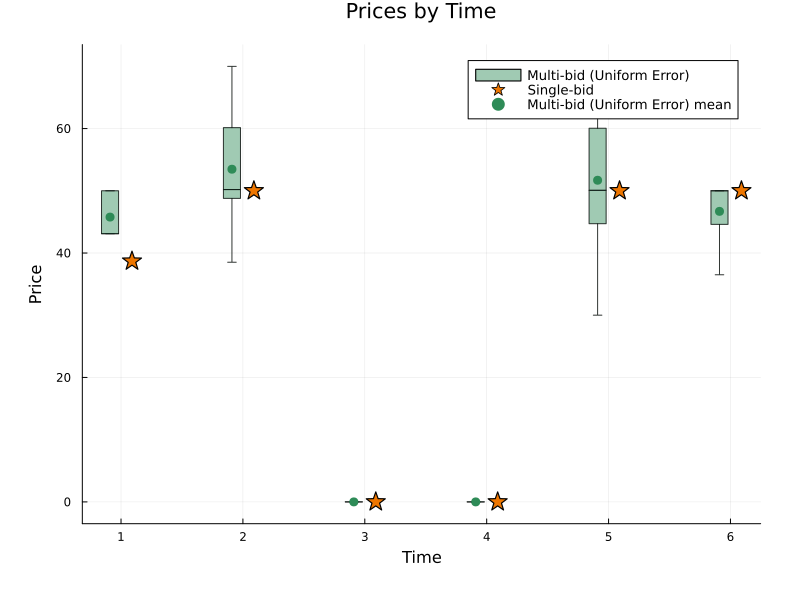

In [8]:
p_price = plot_results_column_by_time(
    [multi_uniform_df, single_df];
    column = :price,
    labels = ["Multi-bid (Uniform Error)", "Single-bid"],
    colors = [:seagreen4, :darkorange2],
    mean_colors = [:seagreen4, :darkorange4],
    offsets = [-0.09, 0.09],
    ylabel = "Price",
    title = "Prices by Time",
    output_path = joinpath(FIGURE_DIR, "prices_by_time.png"),
)
display(p_price)

In [9]:
if has_buy_foresight
    p_price = plot_results_column_by_time(
        [multi_uniform_df_bid_perfect_foresight, single_df_bid_perfect_foresight];
        column = :price,
        labels = ["Multi-bid (Uniform Error)", "Single-bid"],
        colors = [:seagreen4, :darkorange2],
        mean_colors = [:seagreen4, :darkorange4],
        offsets = [-0.09, 0.09],
        ylabel = "Price",
        title = "Prices by Time (Multi-Bid Buy Foresight)",
        output_path = joinpath(FIGURE_DIR, "prices_by_time_buy_foresight.png"),
    )
    display(p_price)
end


# Charging

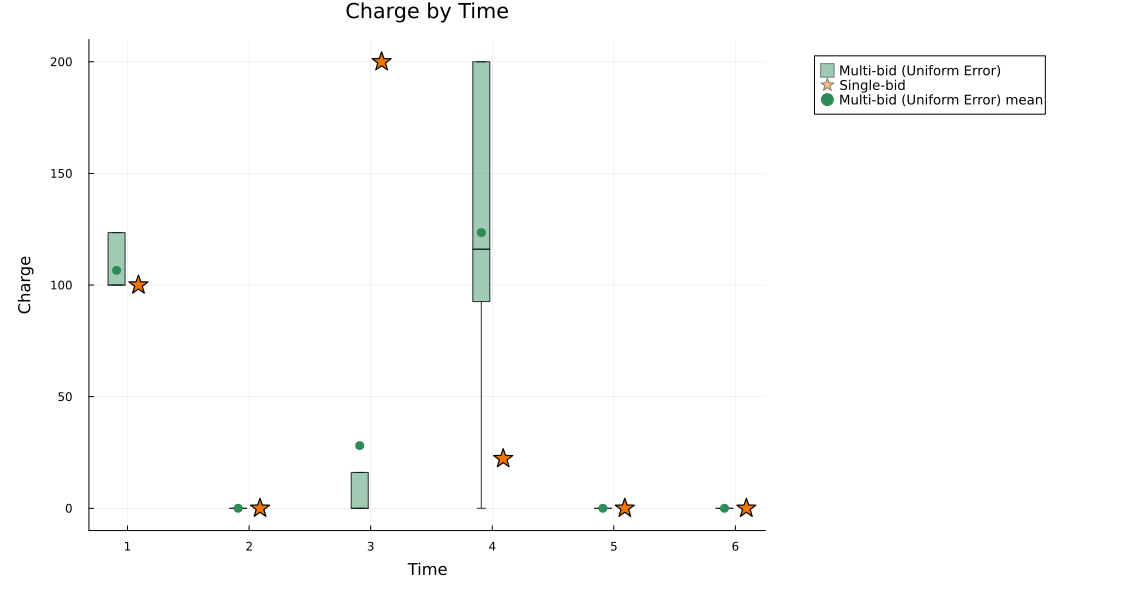

In [10]:
p_charge = plot_results_column_by_time(
    [multi_uniform_df, single_df];
    column = :charge,
    labels = ["Multi-bid (Uniform Error)", "Single-bid"],
    colors = [:seagreen4, :darkorange2],
    mean_colors = [:seagreen4, :darkorange4],
    offsets = [-0.09, 0.09],
    ylabel = "Charge",
    title = "Charge by Time",
    output_path = joinpath(FIGURE_DIR, "charge_by_time.png"),
    outer_legend = true,
)
display(p_charge)


In [11]:
if has_buy_foresight
    p_charge = plot_results_column_by_time(
        [multi_uniform_df_bid_perfect_foresight, single_df_bid_perfect_foresight];
        column = :charge,
        labels = ["Multi-bid buy foresight (Uniform Error)", "Single-bid"],
        colors = [:seagreen4, :darkorange2],
        mean_colors = [:seagreen4, :darkorange4],
        offsets = [-0.09, 0.09],
        ylabel = "Charge",
        title = "Charge by Time",
        output_path = joinpath(FIGURE_DIR, "charge_by_time_buy_foresight.png"),
        outer_legend = true,
    )
    display(p_charge)
end


# ESS Surplus vs. Actual Cost

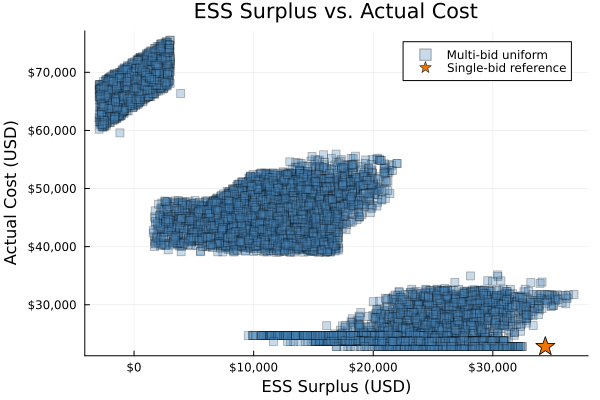

"/Users/nlaws/projects/ferc_841_storage_models/code/figures/bim/ess_surplus_vs_actual_cost.png"

In [12]:

p1 = plot(
    xlabel = "ESS Surplus (USD)",
    ylabel = "Actual Cost (USD)",
    title = "ESS Surplus vs. Actual Cost",
)



scatter!(
    p1,
    multi_uniform_summary_by_sample.multi_uniform_bid_ess_surplus,
    multi_uniform_summary_by_sample.multi_uniform_bid_actual_cost,
    markercolor = :steelblue,
    markershape = :rect,
    alpha = 0.3,
    label = "Multi-bid uniform"
)

scatter!(
    p1,
    single_summary_by_sample.single_bid_ess_surplus,
    single_summary_by_sample.single_bid_actual_cost,
    markercolor = :darkorange2,
    markershape = :star5,
    markersize = 10,
    alpha = 1.0,
    label = "Single-bid reference",
    xformatter = dollar_formatter,
    yformatter = dollar_formatter,
)

display(p1)
savefig(p1, joinpath(FIGURE_DIR, "ess_surplus_vs_actual_cost.png"))


In [13]:
if has_buy_foresight
    p1 = plot(
        xlabel = "ESS Surplus (USD)",
        ylabel = "Actual Cost (USD)",
        title = "ESS Surplus vs. Actual Cost",
    )



    scatter!(
        p1,
        multi_uniform_summary_by_sample_bid_perfect_foresight.multi_uniform_bid_perfect_foresight_ess_surplus,
        multi_uniform_summary_by_sample_bid_perfect_foresight.multi_uniform_bid_perfect_foresight_actual_cost,
        markercolor = :steelblue,
        markershape = :rect,
        alpha = 0.3,
        label = "Multi-bid uniform buy foresight"
    )

    scatter!(
        p1,
        single_summary_by_sample.single_bid_ess_surplus,
        single_summary_by_sample.single_bid_actual_cost,
        markercolor = :darkorange2,
        markershape = :star5,
        markersize = 10,
        alpha = 1.0,
        label = "Single-bid reference",
        xformatter = dollar_formatter,
        yformatter = dollar_formatter,
    )

    display(p1)
    savefig(p1, joinpath(FIGURE_DIR, "ess_surplus_vs_actual_cost_buy_foresight.png"))
end


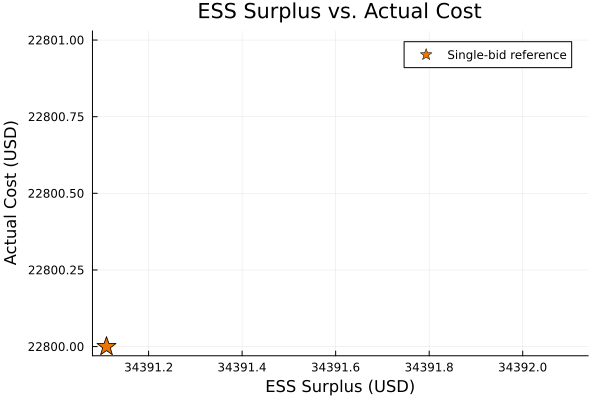

In [14]:
p1 = plot(
    xlabel = "ESS Surplus (USD)",
    ylabel = "Actual Cost (USD)",
    title = "ESS Surplus vs. Actual Cost",
)
scatter!(
    p1,
    single_summary_by_sample.single_bid_ess_surplus,
    single_summary_by_sample.single_bid_actual_cost,
    markercolor = :darkorange2,
    markershape = :star5,
    markersize = 10,
    alpha = 1.0,
    label = "Single-bid reference"
)

In [15]:
p1 = plot(
    xlabel = "Willingness to Pay (USD)",
    ylabel = "Actual Cost (USD)",
    title = "Willingness to Pay vs. Actual Cost",
)
scatter!(
    p1,
    single_summary_by_sample.single_bid_last_ess_bid,
    single_summary_by_sample.single_bid_actual_cost,
    markercolor = :darkorange2,
    markershape = :star5,
    markersize = 10,
    alpha = 1.0,
    label = "Single-bid reference",
    xformatter = dollar_formatter,
    yformatter = dollar_formatter,
)
savefig(p1, joinpath(FIGURE_DIR, "willingness_to_pay_vs_actual_cost.png"))

"/Users/nlaws/projects/ferc_841_storage_models/code/figures/bim/willingness_to_pay_vs_actual_cost.png"

# Histograms

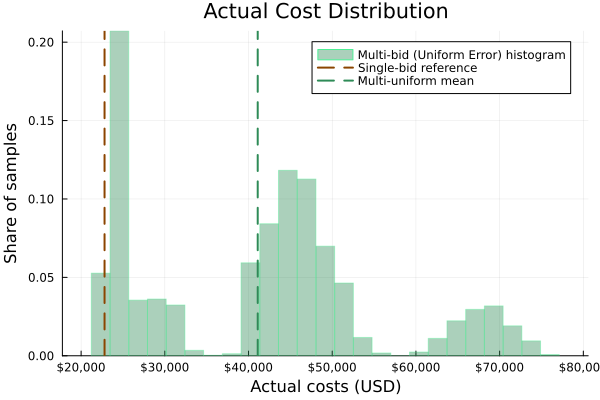

"/Users/nlaws/projects/ferc_841_storage_models/code/figures/bim/actual_cost_distribution.png"

In [16]:
single_vals = single_summary_by_sample.single_bid_actual_cost
multi_uniform_vals = multi_uniform_summary_by_sample.multi_uniform_bid_actual_cost
bins = shared_histogram_bins(single_vals, multi_uniform_vals)

p2 = plot(
    xlabel = "Actual costs (USD)",
    ylabel = "Share of samples",
    title = "Actual Cost Distribution",
    alpha = 0.45,
    color = :darkorange2,
    linecolor = :darkorange4,
    xformatter = dollar_formatter,
)

histogram!(
    p2,
    multi_uniform_vals,
    bins = bins,
    normalize = :probability,
    alpha = 0.4,
    color = :seagreen4,
    linecolor = :seagreen2,
    label = "Multi-bid (Uniform Error) histogram",
    xformatter = dollar_formatter,
)


vline!(p2, single_vals, label = "Single-bid reference",
    linewidth = 2, color = :darkorange4, linestyle = :dash)
vline!(p2, [mean(multi_uniform_vals)], label = "Multi-uniform mean", linewidth = 2, color = :seagreen4, linestyle = :dash)

display(p2)
savefig(p2, joinpath(FIGURE_DIR, "actual_cost_distribution.png"))


In [17]:
if has_buy_foresight
    single_vals = single_summary_by_sample.single_bid_actual_cost
    multi_uniform_vals = multi_uniform_summary_by_sample_bid_perfect_foresight.multi_uniform_bid_perfect_foresight_actual_cost
    bins = shared_histogram_bins(single_vals, multi_uniform_vals)

    p2 = plot(
        xlabel = "Actual costs (USD)",
        ylabel = "Share of samples",
        title = "Actual Cost Distribution",
        alpha = 0.45,
        color = :darkorange2,
        linecolor = :darkorange4,
        xformatter = dollar_formatter,
    )

    histogram!(
        p2,
        multi_uniform_vals,
        bins = bins,
        normalize = :probability,
        alpha = 0.4,
        color = :seagreen4,
        linecolor = :seagreen2,
        label = "Multi-bid (Uniform Error) buy foresight histogram",
        xformatter = dollar_formatter,
    )


    vline!(p2, single_vals, label = "Single-bid reference",
        linewidth = 2, color = :darkorange4, linestyle = :dash)
    vline!(p2, [mean(multi_uniform_vals)], label = "Multi-uniform mean", linewidth = 2, color = :seagreen4, linestyle = :dash)

    display(p2)
    savefig(p2, joinpath(FIGURE_DIR, "actual_cost_distribution_buy_foresight.png"))
end


In [18]:
summary_df = DataFrame(
    metric = [
        "mean_cost_to_serve",
        "median_cost_to_serve",
        "min_cost_to_serve",
        "max_cost_to_serve",
        "mean_actual_cost",
        "median_actual_cost",
        "mean_ess_surplus",
        "median_ess_surplus"
    ],
    single_bid = [
        mean(single_summary_by_sample.single_bid_cost_to_serve),
        median(single_summary_by_sample.single_bid_cost_to_serve),
        minimum(single_summary_by_sample.single_bid_cost_to_serve),
        maximum(single_summary_by_sample.single_bid_cost_to_serve),
        mean(single_summary_by_sample.single_bid_actual_cost),
        median(single_summary_by_sample.single_bid_actual_cost),
        mean(single_summary_by_sample.single_bid_ess_surplus),
        median(single_summary_by_sample.single_bid_ess_surplus)
    ],
    multi_bid = [
        mean(multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve),
        median(multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve),
        minimum(multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve),
        maximum(multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve),
        mean(multi_uniform_summary_by_sample.multi_uniform_bid_actual_cost),
        median(multi_uniform_summary_by_sample.multi_uniform_bid_actual_cost),
        mean(multi_uniform_summary_by_sample.multi_uniform_bid_ess_surplus),
        median(multi_uniform_summary_by_sample.multi_uniform_bid_ess_surplus)
    ]
)
summary_df


Row,metric,single_bid,multi_bid
,String,Float64,Float64
1,mean_cost_to_serve,115476.0,1.21116e5
2,median_cost_to_serve,115476.0,1.20753e5
3,min_cost_to_serve,115476.0,95302.0
4,max_cost_to_serve,115476.0,1.48327e5
5,mean_actual_cost,22800.0,41099.1
6,median_actual_cost,22800.0,43291.9
7,mean_ess_surplus,34391.1,14976.0
8,median_ess_surplus,34391.1,14613.6


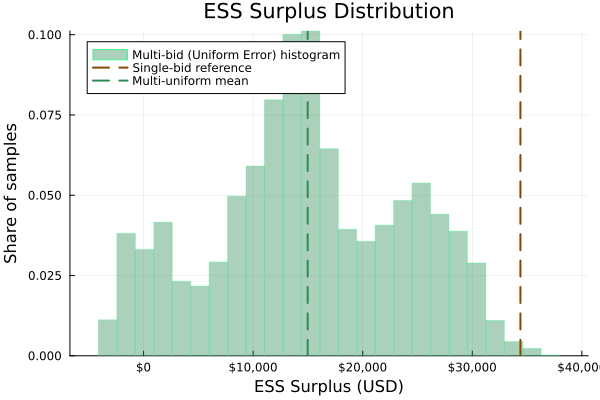

"/Users/nlaws/projects/ferc_841_storage_models/code/figures/bim/ess_surplus_distribution.png"

In [19]:
single_vals = single_summary_by_sample.single_bid_ess_surplus
multi_uniform_vals = multi_uniform_summary_by_sample.multi_uniform_bid_ess_surplus
bins = shared_histogram_bins(single_vals, multi_uniform_vals)

p2 = plot(
    xlabel = "ESS Surplus (USD)",
    ylabel = "Share of samples",
    title = "ESS Surplus Distribution",
    alpha = 0.45,
    color = :darkorange2,
    linecolor = :darkorange4,
    xformatter = dollar_formatter,
)

histogram!(
    p2,
    multi_uniform_vals,
    bins = bins,
    normalize = :probability,
    alpha = 0.4,
    color = :seagreen4,
    linecolor = :seagreen2,
    label = "Multi-bid (Uniform Error) histogram",
    xformatter = dollar_formatter,
)


vline!(p2, single_vals, label = "Single-bid reference",
    linewidth = 2, color = :darkorange4, linestyle = :dash)
vline!(p2, [mean(multi_uniform_vals)], label = "Multi-uniform mean", linewidth = 2, color = :seagreen4, linestyle = :dash)

display(p2)
savefig(p2, joinpath(FIGURE_DIR, "ess_surplus_distribution.png"))


In [20]:
if has_buy_foresight
    single_vals = single_summary_by_sample.single_bid_ess_surplus
    multi_uniform_vals = multi_uniform_summary_by_sample_bid_perfect_foresight.multi_uniform_bid_perfect_foresight_ess_surplus
    bins = shared_histogram_bins(single_vals, multi_uniform_vals)

    p2 = plot(
        xlabel = "ESS Surplus (USD)",
        ylabel = "Share of samples",
        title = "ESS Surplus Distribution",
        alpha = 0.45,
        color = :darkorange2,
        linecolor = :darkorange4,
        xformatter = dollar_formatter,
    )

    histogram!(
        p2,
        multi_uniform_vals,
        bins = bins,
        normalize = :probability,
        alpha = 0.4,
        color = :seagreen4,
        linecolor = :seagreen2,
        label = "Multi-bid (Uniform Error) buy foresight histogram",
        xformatter = dollar_formatter,
    )


    vline!(p2, single_vals, label = "Single-bid reference",
        linewidth = 2, color = :darkorange4, linestyle = :dash)
    vline!(p2, [mean(multi_uniform_vals)], label = "Multi-uniform mean", linewidth = 2, color = :seagreen4, linestyle = :dash)

    display(p2)
    savefig(p2, joinpath(FIGURE_DIR, "ess_surplus_distribution_buy_foresight.png"))
end


# Dispatch

Row,sample,time,soc,charge,discharge,demand,thermal,renewable,price,ess_bid
,Int64,Int64,Float64,Float64,Float64,Float64,Float64,Float64,Float64,Float64
1,8,1,444.44,123.46,0.0,100.0,23.46,200.0,50.0,43.1
2,8,2,0.0,-0.0,100.0,200.0,0.0,100.0,45.47,50.0
3,8,3,57.78,16.05,0.0,300.0,0.0,316.05,-0.0,0.0
4,8,4,777.78,200.0,0.0,300.0,0.0,500.0,-0.0,0.0
5,8,5,0.0,-0.0,175.0,200.0,0.0,25.0,44.24,50.0
6,8,6,-0.0,0.0,0.0,100.0,100.0,-0.0,50.0,40.0


Selected uniform-error multi-bid sample: 8 | cost_to_serve: 111769.69
Single-bid median cost_to_serve: 115476.0


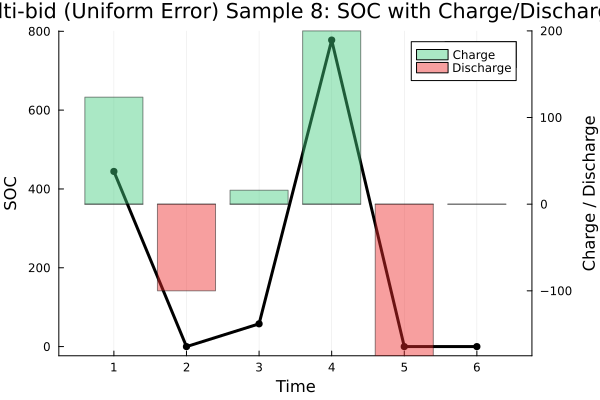

In [21]:
# --- SOC over time for one uniform-error multi-bid sample with cost_to_serve below the single-bid median ---

cost_threshold = median(single_summary_by_sample.single_bid_cost_to_serve)
sample_pick = :random              # :first | :min_cost | :random

sample_cost = DataFrame(sample = multi_uniform_summary_by_sample.sample, sample_cost_to_serve = multi_uniform_summary_by_sample.multi_uniform_bid_cost_to_serve)
eligible = sample_cost[sample_cost.sample_cost_to_serve .< cost_threshold, :]
if isempty(eligible)
    println("No uniform-error multi-bid samples have cost_to_serve below $(cost_threshold); showing the lowest-cost sample.")
    eligible = sample_cost[[argmin(sample_cost.sample_cost_to_serve)], :]
end

chosen_sample =
    sample_pick == :first    ? eligible.sample[1] :
    sample_pick == :min_cost ? eligible.sample[argmin(eligible.sample_cost_to_serve)] :
    sample_pick == :random   ? rand(eligible.sample) :
    error("sample_pick must be :first, :min_cost, or :random")

ts = multi_uniform_df[multi_uniform_df.sample .== chosen_sample, [:sample, :time, :soc, :charge, :discharge, :demand, :thermal, :renewable, :price, :ess_bid]]
sort!(ts, :time)
display(ts)

p = plot(
    ts.time, ts.soc,
    label = "SOC",
    color = :black,
    linewidth = 3,
    marker = :circle,
    xlabel = "Time",
    ylabel = "SOC",
    title = "Multi-bid (Uniform Error) Sample $(chosen_sample): SOC with Charge/Discharge"
)

p_r = twinx(p)

bar!(
    p_r,
    ts.time, ts.charge,
    label = "Charge",
    color = :seagreen3,
    alpha = 0.45,
    ylabel = "Charge / Discharge"
)

bar!(
    p_r,
    ts.time, -ts.discharge,
    label = "Discharge",
    color = :firebrick2,
    alpha = 0.45
)

chosen_cost = eligible.sample_cost_to_serve[findfirst(==(chosen_sample), eligible.sample)]
println("Selected uniform-error multi-bid sample: ", chosen_sample, " | cost_to_serve: ", round(chosen_cost, digits = 2))
println("Single-bid median cost_to_serve: ", round(cost_threshold, digits = 2))

display(p)
